# Proyek Analisis Data: Bike Sharing Dataset

**Nama:** Abdillah Abhipraya Abrar 
**Email:** abdillahabhi13@gmail.com 
**ID Dicoding:** abhipraya29

## Deskripsi Proyek

Proyek ini menganalisis pola permintaan layanan bike sharing di Washington D.C., Amerika Serikat, menggunakan **Bike Sharing Dataset** periode **2011–2012**. Dataset berisi agregasi harian (`day.csv`, 731 baris) dan per jam (`hour.csv`, 17.379 baris) dari sistem Capital Bikeshare.

Analisis difokuskan pada tiga pertanyaan bisnis yang saling melengkapi: pola permintaan per jam, pengaruh cuaca terhadap permintaan harian, dan segmentasi pengguna casual vs registered. Hasil analisis diharapkan dapat membantu tim operasional dan pemasaran dalam mengatur ketersediaan sepeda, kampanye membership, serta perencanaan armada.

**Sumber data:** [UCI Machine Learning Repository — Bike Sharing Dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) — Fanaee-T & Gama (2013).

## 1. Business Questions

Berikut tiga pertanyaan bisnis yang dirumuskan dengan kerangka **SMART** (Specific, Measurable, Action-Oriented, Relevant, Time-bound).

### Pertanyaan 1 — Pola permintaan per jam

> **Bagaimana pola rata-rata penyewaan sepeda per jam pada hari kerja dibandingkan akhir pekan/libur di Washington D.C. selama 2011–2012, dan pada jam berapa puncak permintaan terjadi pada masing-masing tipe hari?**

- **Specific:** fokus pada pola per jam dan perbandingan hari kerja vs akhir pekan/libur.
- **Measurable:** dihitung dari rata-rata `cnt` per jam dan jam dengan rata-rata tertinggi.
- **Action-Oriented:** hasilnya menentukan jam dan lokasi penambahan armada/staf.
- **Relevant:** berkaitan langsung dengan ketersediaan sepeda dan kepuasan pengguna.
- **Time-bound:** periode 1 Januari 2011–31 Desember 2012.

### Pertanyaan 2 — Pengaruh cuaca

> **Seberapa besar perbedaan rata-rata penyewaan sepeda harian berdasarkan kondisi cuaca (cerah/berawan, berkabut/mendung, hujan/salju ringan) dan faktor cuaca mana (suhu, kelembapan, kecepatan angin) yang paling berkorelasi dengan permintaan selama 2011–2012?**

- **Specific:** fokus pada kondisi cuaca dan tiga faktor cuaca utama.
- **Measurable:** rata-rata `cnt` harian, persentase penurunan vs cuaca cerah, dan koefisien korelasi.
- **Action-Oriented:** menjadi dasar rencana operasional dan promosi berbasis cuaca.
- **Relevant:** cuaca adalah faktor eksternal utama yang memengaruhi permintaan bike sharing.
- **Time-bound:** periode 2011–2012.

### Pertanyaan 3 — Segmen pengguna

> **Bagaimana komposisi dan pola penyewaan pengguna casual versus registered berdasarkan musim dan tipe hari selama 2011–2012, dan segmen mana yang paling berpotensi ditingkatkan?**

- **Specific:** fokus pada dua tipe pengguna, musim, dan tipe hari.
- **Measurable:** total dan proporsi penyewaan, serta pertumbuhan year-over-year (YoY).
- **Action-Oriented:** membantu merancang kampanye konversi casual menjadi registered.
- **Relevant:** mendukung pertumbuhan pelanggan dan pendapatan berulang.
- **Time-bound:** periode 2011–2012.

### Ringkasan SMART

| Elemen | Pertanyaan 1 | Pertanyaan 2 | Pertanyaan 3 |
|---|---|---|---|
| Specific | Pola per jam, hari kerja vs akhir pekan | Kondisi & faktor cuaca | Casual vs registered per musim/tipe hari |
| Measurable | Rata-rata cnt/jam, jam puncak | Rata-rata cnt/hari, % penurunan, korelasi | Total, proporsi, pertumbuhan YoY |
| Action-Oriented | Penjadwalan armada & staf | Rencana operasional berbasis cuaca | Kampanye konversi membership |
| Relevant | Ketersediaan sepeda | Perencanaan permintaan | Retensi & pendapatan berulang |
| Time-bound | 2011–2012 | 2011–2012 | 2011–2012 |

## 2. Data Wrangling

### 2.1 Gathering Data

Pada tahap ini, dua berkas dataset dimuat ke dalam DataFrame:

- `day.csv` — agregasi harian (731 baris, 16 kolom).
- `hour.csv` — agregasi per jam (17.379 baris, 17 kolom).

Kedua berkas memiliki kolom yang sama, kecuali `hr` yang hanya ada pada `hour.csv`. Kolom `cnt` adalah jumlah total penyewaan dan seharusnya sama dengan `casual + registered`.

In [1]:
%matplotlib inline

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

PALETTE = {
    "primary": "#2A6F97",
    "secondary": "#61A5C2",
    "accent": "#F4A261",
    "danger": "#C44536",
    "muted": "#8D99AE",
    "dark": "#1D3557",
}

DATA_DIR = Path("data")
DASHBOARD_DIR = Path("dashboard")

In [2]:
day_df = pd.read_csv(DATA_DIR / "day.csv")
hour_df = pd.read_csv(DATA_DIR / "hour.csv")

print(f"day.csv  : {day_df.shape[0]:,} baris x {day_df.shape[1]} kolom")
print(f"hour.csv : {hour_df.shape[0]:,} baris x {hour_df.shape[1]} kolom")
print(f"Periode day.csv : {day_df['dteday'].min()} s.d. {day_df['dteday'].max()}")
print(f"Periode hour.csv: {hour_df['dteday'].min()} s.d. {hour_df['dteday'].max()}")

display(day_df.head())
display(hour_df.head())

day.csv  : 731 baris x 16 kolom
hour.csv : 17,379 baris x 17 kolom
Periode day.csv : 2011-01-01 s.d. 2012-12-31
Periode hour.csv: 2011-01-01 s.d. 2012-12-31


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.34,0.36,0.81,0.16,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.36,0.35,0.70,0.25,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.20,0.19,0.44,0.25,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.20,0.21,0.59,0.16,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.23,0.23,0.44,0.19,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.29,0.81,0.00,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.27,0.80,0.00,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.27,0.80,0.00,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.29,0.75,0.00,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.29,0.75,0.00,0,1,1


### 2.2 Assessing Data

Pemeriksaan kualitas data dilakukan dengan beberapa pendekatan:

1. `info()` untuk melihat tipe data dan jumlah baris.
2. `isna().sum()` untuk mendeteksi missing value.
3. `duplicated()` untuk mendeteksi duplikasi baris/tanggal.
4. Pemeriksaan nilai tidak valid (mis. kelembapan 0%).
5. Pemeriksaan konsistensi `cnt = casual + registered`.
6. Pemeriksaan kelengkapan timestamp per jam.
7. Deteksi outlier dengan metode IQR.

In [3]:
print("=== INFO day_df ===")
day_df.info()
print("\n=== INFO hour_df ===")
hour_df.info()

print("\n=== MISSING VALUE ===")
missing = pd.DataFrame({
    "day_df": day_df.isna().sum(),
    "hour_df": hour_df.isna().sum(),
})
display(missing.T)

print("Jumlah duplikat baris day_df :", day_df.duplicated().sum())
print("Jumlah duplikat baris hour_df:", hour_df.duplicated().sum())

=== INFO day_df ===
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB

=== INFO hour_df ===
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
D

,atemp,casual,cnt,dteday,holiday,hr,hum,instant,mnth,registered,season,temp,weathersit,weekday,windspeed,workingday,yr
day_df,0.00,0.00,0.00,0.00,0.00,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
hour_df,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


Jumlah duplikat baris day_df : 0
Jumlah duplikat baris hour_df: 0


In [4]:
day_date = pd.to_datetime(day_df["dteday"])
hour_date = pd.to_datetime(hour_df["dteday"])

print("Tanggal unik day_df :", day_date.nunique(), "dari", len(day_df), "baris")
print("Tanggal unik hour_df:", hour_date.nunique(), "dari", len(hour_df), "baris")
print("Duplikat tanggal day_df :", day_date.duplicated().sum())
print("Duplikat timestamp hour_df:", hour_df.duplicated(["dteday", "hr"]).sum())

expected_hours = pd.MultiIndex.from_product(
    [pd.date_range(day_date.min(), day_date.max(), freq="D"), range(24)],
    names=["dteday", "hr"],
)
hour_ts = hour_df.assign(dteday=pd.to_datetime(hour_df["dteday"]))[["dteday", "hr"]]
actual_hours = pd.MultiIndex.from_frame(hour_ts)
missing_hours = expected_hours.difference(actual_hours)
print(f"Timestamp jam yang hilang: {len(missing_hours):,} dari {len(expected_hours):,} kemungkinan")

missing_hour_dist = (
    pd.Series([timestamp[1] for timestamp in missing_hours], name="jumlah_hilang")
    .value_counts()
    .sort_index()
    .rename_axis("jam")
    .to_frame()
)
print("\nSebaran timestamp yang hilang per jam:")
display(missing_hour_dist.T)

print("\nNilai hum = 0 (tidak valid):")
print("day_df :", (day_df["hum"] == 0).sum())
print("hour_df:", (hour_df["hum"] == 0).sum())

print("\nKonsistensi cnt = casual + registered:")
print("day_df :", (day_df["cnt"] != day_df["casual"] + day_df["registered"]).sum(), "baris tidak konsisten")
print("hour_df:", (hour_df["cnt"] != hour_df["casual"] + hour_df["registered"]).sum(), "baris tidak konsisten")

print("\nNilai unik kategori:")
print("season     :", sorted(day_df["season"].unique()))
print("weathersit :", sorted(day_df["weathersit"].unique()))
print("weekday    :", sorted(day_df["weekday"].unique()))
print("yr         :", sorted(day_df["yr"].unique()))

print("\nOutlier cnt dengan metode IQR:")
for name, series in [("day_df", day_df["cnt"]), ("hour_df", hour_df["cnt"])]:
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier = ((series < lower) | (series > upper)).sum()
    print(f"{name}: batas [{lower:,.1f}, {upper:,.1f}], outlier = {outlier:,}")

Tanggal unik day_df : 731 dari 731 baris
Tanggal unik hour_df: 731 dari 17379 baris
Duplikat tanggal day_df : 0
Duplikat timestamp hour_df: 0
Timestamp jam yang hilang: 165 dari 17,544 kemungkinan

Sebaran timestamp yang hilang per jam:


jam,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
count,5,7,16,34,34,14,6,4,4,4,4,4,3,2,2,2,1,1,3,3,3,3,3,3



Nilai hum = 0 (tidak valid):
day_df : 1
hour_df: 22

Konsistensi cnt = casual + registered:
day_df : 0 baris tidak konsisten
hour_df: 0 baris tidak konsisten

Nilai unik kategori:
season     : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
weathersit : [np.int64(1), np.int64(2), np.int64(3)]
weekday    : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
yr         : [np.int64(0), np.int64(1)]

Outlier cnt dengan metode IQR:
day_df: batas [-1,054.0, 10,162.0], outlier = 0
hour_df: batas [-321.5, 642.5], outlier = 505


**Ringkasan temuan Assessing Data:**

| No | Permasalahan | Temuan | Dampak | Rencana Penanganan |
|---|---|---|---|---|
| 1 | Tipe data tidak tepat | `dteday` masih bertipe teks/object | Analisis berbasis waktu tidak bisa dilakukan | Konversi ke datetime |
| 2 | Missing value | Tidak ada NaN pada kedua berkas | — | Tidak ada tindakan |
| 3 | Duplikasi | Tidak ada duplikasi baris/tanggal | — | Tidak ada tindakan |
| 4 | Nilai tidak valid | Kelembapan 0% pada 1 hari dan 22 baris per jam | 0% tidak realistis secara fisik | Imputasi dengan median bulan (dan median bulan-jam) |
| 5 | Kategori tidak konsisten | `season`, `weathersit`, `weekday`, `yr` masih berupa kode angka | Sulit dibaca dan berisiko salah interpretasi | Mapping ke label yang jelas |
| 6 | Satuan tidak standar | `temp`, `atemp`, `hum`, `windspeed` masih ternormalisasi | Angka sulit diinterpretasikan oleh stakeholder | Konversi ke °C, %, dan km/jam |
| 7 | Kelengkapan data | 165 timestamp per jam hilang, sebagian besar pukul 03.00–04.00 | Analisis per jam sedikit tidak lengkap | Tidak diimputasi; agregasi per jam dilakukan dan keterbatasan dicatat |
| 8 | Outlier | 505 outlier per jam; 0 outlier harian (IQR) | Lonjakan permintaan bisa terlihat ekstrem | Dipertahankan karena merupakan permintaan valid, bukan kesalahan input |
| 9 | Konsistensi | `cnt = casual + registered` pada seluruh baris | — | Tidak ada tindakan |

Minimal dua permasalahan utama telah teridentifikasi: **nilai tidak valid (kelembapan 0%)**, **kategori/satuan tidak konsisten**, **kelengkapan timestamp**, dan **outlier**.

### 2.3 Cleaning Data

Tindakan pembersihan yang dilakukan:

1. Mengubah `dteday` menjadi tipe datetime.
2. Mengubah kode kategori (`season`, `weathersit`, `weekday`, `yr`) menjadi label yang mudah dibaca.
3. Mengonversi nilai ternormalisasi ke satuan asli: suhu (°C), kelembapan (%), dan kecepatan angin (km/jam).
4. Mengisi kelembapan 0% dengan median bulan (dan median bulan-jam untuk data per jam) karena 0% tidak realistis.
5. Menambahkan fitur turunan: `year`, `month`, `day_type`, `time_block`, `casual_share_pct`, dan `demand_segment`.
6. Tidak menghapus baris; seluruh 731 data harian dan 17.379 data per jam dipertahankan. Outlier per jam tidak dihapus karena merepresentasikan lonjakan permintaan yang valid.
7. Menyimpan data bersih ke folder `dashboard/` untuk digunakan oleh Streamlit.

> Catatan: label musim mengikuti dokumentasi dataset (season 1 = springer, 2 = summer, 3 = fall, 4 = winter). Pada data ini season 1 mencakup Januari–Maret.

In [5]:
season_map = {
    1: "Spring (Jan-Mar)",
    2: "Summer (Apr-Jun)",
    3: "Fall (Jul-Sep)",
    4: "Winter (Oct-Dec)",
}
weather_map = {
    1: "Cerah/Berawan",
    2: "Berkabut/Mendung",
    3: "Hujan/Salju Ringan",
    4: "Hujan/Salju Lebat",
}
weekday_map = {
    0: "Senin", 1: "Selasa", 2: "Rabu", 3: "Kamis",
    4: "Jumat", 5: "Sabtu", 6: "Minggu",
}
yr_map = {0: 2011, 1: 2012}


def clean_common(df):
    df = df.copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    df["year"] = df["yr"].map(yr_map)
    df["month"] = df["dteday"].dt.month
    df["month_name"] = df["dteday"].dt.strftime("%b")
    df["weekday_name"] = df["weekday"].map(weekday_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    df["season_label"] = df["season"].map(season_map)
    df["weather_label"] = df["weathersit"].map(weather_map)
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67
    return df


day_clean = clean_common(day_df)
hour_clean = clean_common(hour_df)

month_median = day_clean.loc[day_clean["hum_pct"] > 0].groupby("month")["hum_pct"].median()
mask = day_clean["hum_pct"] == 0
day_clean.loc[mask, "hum_pct"] = day_clean.loc[mask, "month"].map(month_median)

month_hour_median = (
    hour_clean.loc[hour_clean["hum_pct"] > 0]
    .groupby(["month", "hr"])["hum_pct"]
    .median()
)
mask = hour_clean["hum_pct"] == 0
keys = list(zip(hour_clean.loc[mask, "month"], hour_clean.loc[mask, "hr"]))
hour_clean.loc[mask, "hum_pct"] = [
    month_hour_median.get(key, hour_clean["hum_pct"].median()) for key in keys
]

day_clean["casual_share_pct"] = day_clean["casual"] / day_clean["cnt"] * 100
day_clean["demand_segment"] = pd.qcut(
    day_clean["cnt"], q=4, labels=["Low", "Medium", "High", "Very High"]
)

hour_clean["datetime"] = hour_clean["dteday"] + pd.to_timedelta(hour_clean["hr"], unit="h")
hour_clean["time_block"] = pd.cut(
    hour_clean["hr"],
    bins=[-1, 5, 9, 15, 19, 23],
    labels=["Malam (00-05)", "Pagi (06-09)", "Siang (10-15)", "Sore (16-19)", "Malam (20-23)"],
)
hour_clean["casual_share_pct"] = hour_clean["casual"] / hour_clean["cnt"] * 100

print("Jumlah hum = 0 setelah cleaning:")
print("day_clean :", (day_clean["hum_pct"] == 0).sum())
print("hour_clean:", (hour_clean["hum_pct"] == 0).sum())
print("\nKonsistensi cnt setelah cleaning:")
print("day_clean :", (day_clean["cnt"] != day_clean["casual"] + day_clean["registered"]).sum())
print("hour_clean:", (hour_clean["cnt"] != hour_clean["casual"] + hour_clean["registered"]).sum())
print("\nRentang nilai setelah konversi satuan:")
display(day_clean[["temp_c", "hum_pct", "windspeed_kmh"]].describe().round(2))

Jumlah hum = 0 setelah cleaning:
day_clean : 0
hour_clean: 0

Konsistensi cnt setelah cleaning:
day_clean : 0
hour_clean: 0

Rentang nilai setelah konversi satuan:


,temp_c,hum_pct,windspeed_kmh
count,731.00,731.00,731.00
mean,20.31,62.87,12.76
std,7.51,14.05,5.19
min,2.42,18.79,1.50
25%,13.82,52.10,9.04
50%,20.43,62.67,12.13
75%,26.87,73.02,15.63
max,35.33,97.25,34.00


In [6]:
DASHBOARD_DIR.mkdir(exist_ok=True)
day_clean.to_csv(DASHBOARD_DIR / "main_data_daily.csv", index=False)
hour_clean.to_csv(DASHBOARD_DIR / "main_data.csv", index=False)

print("Data bersih disimpan ke:")
print("-", DASHBOARD_DIR / "main_data.csv")
print("-", DASHBOARD_DIR / "main_data_daily.csv")

Data bersih disimpan ke:
- dashboard\main_data.csv
- dashboard\main_data_daily.csv


Setelah cleaning:

- Tidak ada lagi kelembapan 0%.
- `cnt` konsisten dengan `casual + registered` pada seluruh baris.
- Satuan suhu, kelembapan, dan angin sudah interpretable.
- Data siap digunakan untuk EDA dan dashboard.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Pertanyaan 1 — Pola permintaan per jam

Untuk menjawab Pertanyaan 1, data per jam dikelompokkan berdasarkan `day_type` dan `hr`, lalu dihitung rata-rata `cnt`. Blok waktu juga dibuat secara manual (manual grouping) untuk melihat pola pagi/siang/sore/malam.

In [7]:
hourly_pattern = (
    hour_clean.groupby(["day_type", "hr"], as_index=False)
    .agg(
        avg_rentals=("cnt", "mean"),
        avg_casual=("casual", "mean"),
        avg_registered=("registered", "mean"),
    )
)

hourly_pivot = hourly_pattern.pivot(index="hr", columns="day_type", values="avg_rentals").round(1)
display(hourly_pivot)

peak_hours = (
    hourly_pattern.loc[hourly_pattern.groupby("day_type")["avg_rentals"].idxmax()]
    .rename(columns={"hr": "jam_puncak", "avg_rentals": "rata_rata_puncak"})
)
low_hours = (
    hourly_pattern.loc[hourly_pattern.groupby("day_type")["avg_rentals"].idxmin()]
    .rename(columns={"hr": "jam_terendah", "avg_rentals": "rata_rata_terendah"})
)
print("Jam puncak per tipe hari:")
display(peak_hours[["day_type", "jam_puncak", "rata_rata_puncak"]])
print("Jam terendah per tipe hari:")
display(low_hours[["day_type", "jam_terendah", "rata_rata_terendah"]])

for day_type in ["Hari Kerja", "Akhir Pekan/Libur"]:
    subset = hourly_pattern[hourly_pattern["day_type"] == day_type]
    peak = subset.loc[subset["avg_rentals"].idxmax()]
    low = subset.loc[subset["avg_rentals"].idxmin()]
    print(
        f"{day_type}: puncak {peak['hr']:.0f}:00 ({peak['avg_rentals']:.1f} sepeda/jam), "
        f"terendah {low['hr']:.0f}:00 ({low['avg_rentals']:.1f} sepeda/jam), "
        f"rasio {peak['avg_rentals'] / low['avg_rentals']:.1f}x"
    )

time_block_pattern = (
    hour_clean.groupby(["day_type", "time_block"], observed=True)
    .agg(rata_rata=("cnt", "mean"))
    .round(1)
)
print("\nRata-rata penyewaan per blok waktu:")
display(time_block_pattern)

day_type,Akhir Pekan/Libur,Hari Kerja
hr,,
0,90.80,36.80
1,69.50,16.60
2,53.20,8.70
3,25.80,4.90
4,8.30,5.40
5,8.70,24.90
6,18.70,102.50
7,43.40,290.60
8,105.70,477.00


Jam puncak per tipe hari:


,day_type,jam_puncak,rata_rata_puncak
13,Akhir Pekan/Libur,13,372.73
41,Hari Kerja,17,525.29


Jam terendah per tipe hari:


,day_type,jam_terendah,rata_rata_terendah
4,Akhir Pekan/Libur,4,8.26
27,Hari Kerja,3,4.94


Hari Kerja: puncak 17:00 (525.3 sepeda/jam), terendah 3:00 (4.9 sepeda/jam), rasio 106.3x
Akhir Pekan/Libur: puncak 13:00 (372.7 sepeda/jam), terendah 4:00 (8.3 sepeda/jam), rasio 45.1x

Rata-rata penyewaan per blok waktu:


rata_rata
day_type          time_block              
Akhir Pekan/Libur Malam (00-05)      43.00
                  Pagi (06-09)       85.00
                  Siang (10-15)     338.90
                  Sore (16-19)      297.30
                  Malam (20-23)     129.70
Hari Kerja        Malam (00-05)      16.40
                  Pagi (06-09)      277.90
                  Siang (10-15)     179.70
                  Sore (16-19)      414.80
                  Malam (20-23)     165.80

**Insight Pertanyaan 1:**

- Pada **hari kerja**, pola permintaan bersifat **bimodal**: puncak pagi sekitar **08.00 (477 sepeda/jam)** dan puncak sore pada **17.00 (525,3 sepeda/jam)**. Permintaan terendah terjadi pada **03.00 (4,9 sepeda/jam)**.
- Pada **akhir pekan/libur**, pola lebih landai dengan satu puncak di **13.00 (372,7 sepeda/jam)** dan titik terendah pada **04.00 (8,3 sepeda/jam)**.
- Rasio puncak terhadap titik terendah mencapai **106,3x** pada hari kerja dan **45,1x** pada akhir pekan.
- Blok **sore (16.00–19.00)** pada hari kerja memiliki rata-rata tertinggi (**414,8 sepeda/jam**), sedangkan blok **siang (10.00–15.00)** mendominasi akhir pekan (**338,9 sepeda/jam**).
- Pengguna **registered** mendominasi puncak hari kerja (468,4 sepeda/jam pada 17.00), sedangkan pengguna **casual** memuncak lebih siang pada akhir pekan (139,6 sepeda/jam pada 14.00).

### 3.2 Pertanyaan 2 — Pengaruh cuaca

Analisis dilakukan dengan mengelompokkan data harian berdasarkan `weather_label`, menghitung korelasi Pearson antara `cnt` dan variabel cuaca, serta membagi suhu ke dalam beberapa interval.

In [8]:
weather_daily = (
    day_clean.groupby("weather_label")
    .agg(
        jumlah_hari=("cnt", "size"),
        rata_rata=("cnt", "mean"),
        median=("cnt", "median"),
        total=("cnt", "sum"),
    )
    .sort_values("rata_rata", ascending=False)
    .round(1)
)
weather_daily["penurunan_vs_cerah_pct"] = (
    weather_daily["rata_rata"] / weather_daily.loc["Cerah/Berawan", "rata_rata"] - 1
) * 100
display(weather_daily)

corr_cols = ["cnt", "temp_c", "atemp_c", "hum_pct", "windspeed_kmh"]
corr_matrix = day_clean[corr_cols].corr().round(3)
display(corr_matrix)
print("Korelasi terhadap cnt:")
display(corr_matrix["cnt"].sort_values(ascending=False).to_frame())

temp_bins = pd.cut(
    day_clean["temp_c"],
    bins=[0, 10, 20, 30, 41],
    labels=["0-10°C", "10-20°C", "20-30°C", "30-41°C"],
)
temp_profile = (
    day_clean.groupby(temp_bins, observed=True)
    .agg(jumlah_hari=("cnt", "size"), rata_rata=("cnt", "mean"))
    .round(1)
)
print("\nRata-rata penyewaan berdasarkan rentang suhu:")
display(temp_profile)

,jumlah_hari,rata_rata,median,total,penurunan_vs_cerah_pct
weather_label,,,,,
Cerah/Berawan,463,"4,876.80","4,844.00",2257952,0.00
Berkabut/Mendung,247,"4,035.90","4,040.00",996858,-17.24
Hujan/Salju Ringan,21,"1,803.30","1,817.00",37869,-63.02


,cnt,temp_c,atemp_c,hum_pct,windspeed_kmh
cnt,1.00,0.63,0.63,-0.11,-0.23
temp_c,0.63,1.00,0.99,0.12,-0.16
atemp_c,0.63,0.99,1.00,0.14,-0.18
hum_pct,-0.11,0.12,0.14,1.00,-0.25
windspeed_kmh,-0.23,-0.16,-0.18,-0.25,1.00


Korelasi terhadap cnt:


,cnt
cnt,1.00
atemp_c,0.63
temp_c,0.63
hum_pct,-0.11
windspeed_kmh,-0.23



Rata-rata penyewaan berdasarkan rentang suhu:


,jumlah_hari,rata_rata
temp_c,,
0-10°C,60,"1,677.80"
10-20°C,299,"3,692.30"
20-30°C,300,"5,661.70"
30-41°C,72,"5,410.00"


**Insight Pertanyaan 2:**

- Cuaca cerah/berawan menghasilkan rata-rata **4.876,8 penyewaan/hari** (463 hari).
- Cuaca berkabut/mendung menurunkan rata-rata menjadi **4.035,9/hari** atau **-17,2%** dibanding cuaca cerah (247 hari).
- Hujan/salju ringan menurunkan rata-rata drastis menjadi **1.803,3/hari** atau **-63,0%** (21 hari).
- Suhu aktual (**r = 0,627**) dan suhu efektif/`atemp` (**r = 0,631**) memiliki korelasi positif kuat dan hampir identik; keduanya menunjukkan bahwa suhu adalah faktor cuaca yang paling berkorelasi dengan permintaan.
- Kelembapan (**r = -0,113**) dan kecepatan angin (**r = -0,235**) memiliki korelasi negatif lemah.
- Rata-rata penyewaan tertinggi terjadi pada suhu **20–30°C (5.661,7/hari)**; suhu **0–10°C** hanya **1.677,8/hari**.
- Perlu dicatat bahwa korelasi bukan berarti kausalitas dan jumlah hari hujan hanya 21 hari, sehingga estimasi untuk kondisi ekstrem perlu hati-hati.

### 3.3 Pertanyaan 3 — Segmen pengguna casual vs registered

Data harian dikelompokkan berdasarkan musim dan tipe hari untuk membandingkan total serta proporsi penyewaan casual dan registered. Pertumbuhan YoY juga dihitung untuk melihat segmen yang tumbuh lebih cepat.

In [9]:
season_order = ["Spring (Jan-Mar)", "Summer (Apr-Jun)", "Fall (Jul-Sep)", "Winter (Oct-Dec)"]
seg_order = ["Low", "Medium", "High", "Very High"]

user_season = (
    day_clean.groupby("season_label")
    .agg(casual=("casual", "sum"), registered=("registered", "sum"))
    .assign(
        total=lambda x: x["casual"] + x["registered"],
        casual_share_pct=lambda x: x["casual"] / x["total"] * 100,
        registered_share_pct=lambda x: x["registered"] / x["total"] * 100,
    )
    .reindex(season_order)
    .round(1)
)
print("Komposisi pengguna per musim:")
display(user_season)

user_daytype = (
    day_clean.groupby("day_type")
    .agg(casual=("casual", "sum"), registered=("registered", "sum"))
    .assign(
        total=lambda x: x["casual"] + x["registered"],
        casual_share_pct=lambda x: x["casual"] / x["total"] * 100,
        registered_share_pct=lambda x: x["registered"] / x["total"] * 100,
    )
    .round(1)
)
print("Komposisi pengguna per tipe hari:")
display(user_daytype)

overall_share = day_clean[["casual", "registered", "cnt"]].sum()
print(f"Total casual     : {overall_share['casual']:,.0f} ({overall_share['casual'] / overall_share['cnt'] * 100:.1f}%)")
print(f"Total registered : {overall_share['registered']:,.0f} ({overall_share['registered'] / overall_share['cnt'] * 100:.1f}%)")

yoy_user = day_clean.groupby("year").agg(
    total=("cnt", "sum"), casual=("casual", "sum"), registered=("registered", "sum")
)
print("\nTotal penyewaan per tahun:")
display(yoy_user)
print(f"Pertumbuhan total 2011→2012      : {(yoy_user.loc[2012, 'total'] / yoy_user.loc[2011, 'total'] - 1) * 100:.1f}%")
print(f"Pertumbuhan casual 2011→2012     : {(yoy_user.loc[2012, 'casual'] / yoy_user.loc[2011, 'casual'] - 1) * 100:.1f}%")
print(f"Pertumbuhan registered 2011→2012 : {(yoy_user.loc[2012, 'registered'] / yoy_user.loc[2011, 'registered'] - 1) * 100:.1f}%")

day_clean["quarter"] = day_clean["dteday"].dt.quarter
quarterly = day_clean.pivot_table(index="quarter", columns="year", values="cnt", aggfunc="sum")
quarterly["yoy_pct"] = (quarterly[2012] / quarterly[2011] - 1) * 100
print("\nPertumbuhan YoY per kuartal:")
display(quarterly.round(1))

Komposisi pengguna per musim:


,casual,registered,total,casual_share_pct,registered_share_pct
season_label,,,,,
Spring (Jan-Mar),60622,410726,471348,12.90,87.10
Summer (Apr-Jun),203522,715067,918589,22.20,77.80
Fall (Jul-Sep),226091,835038,1061129,21.30,78.70
Winter (Oct-Dec),129782,711831,841613,15.40,84.60


Komposisi pengguna per tipe hari:


,casual,registered,total,casual_share_pct,registered_share_pct
day_type,,,,,
Akhir Pekan/Libur,316732,683537,1000269,31.70,68.30
Hari Kerja,303285,1989125,2292410,13.20,86.80


Total casual     : 620,017 (18.8%)
Total registered : 2,672,662 (81.2%)

Total penyewaan per tahun:


,total,casual,registered
year,,,
2011,1243103,247252,995851
2012,2049576,372765,1676811


Pertumbuhan total 2011→2012      : 64.9%
Pertumbuhan casual 2011→2012     : 50.8%
Pertumbuhan registered 2011→2012 : 68.4%

Pertumbuhan YoY per kuartal:


year,2011,2012,yoy_pct
quarter,,,
1,150449,364756,142.40
2,374203,572919,53.10
3,405450,636683,57.00
4,313001,475218,51.80


**Insight Pertanyaan 3:**

- Secara keseluruhan, **registered** menyumbang **2.672.662 penyewaan (81,2%)**, sedangkan **casual** menyumbang **620.017 (18,8%)**.
- Proporsi casual lebih tinggi pada **akhir pekan/libur (31,7%)** dibanding **hari kerja (13,2%)**.
- Berdasarkan musim, proporsi casual tertinggi terjadi pada **Summer (22,2%)** dan **Fall (21,3%)**, lalu **Winter (15,4%)** dan **Spring (12,9%)**.
- Total penyewaan tumbuh **64,9%** dari 2011 ke 2012; segmen **registered tumbuh 68,4%**, lebih cepat dari **casual 50,8%**.
- Pertumbuhan YoY per kuartal: **Q1 +142,4%**, **Q2 +53,1%**, **Q3 +57,0%**, dan **Q4 +51,8%**. Q1 2011 sangat rendah karena faktor musim dingin dan kemungkinan efek awal operasional.
- Implikasi: pengguna registered adalah tulang punggung pendapatan, tetapi pengguna casual di akhir pekan dan musim hangat adalah target utama untuk konversi membership.

## 4. Analisis Lanjutan: Segmentasi Permintaan (Binning)

Teknik analisis lanjutan yang digunakan adalah **clustering melalui binning** (tanpa machine learning). Data harian dibagi menjadi empat segmen berdasarkan kuartil `cnt`:

- **Low**: 22–3.141 penyewaan/hari
- **Medium**: 3.163–4.548
- **High**: 4.549–5.936
- **Very High**: 5.976–8.714

Tujuannya adalah memahami karakteristik hari pada setiap tingkat permintaan sehingga tim operasional dapat mengambil keputusan yang berbeda untuk tiap segmen.

In [10]:
segment_profile = (
    day_clean.groupby("demand_segment", observed=True)
    .agg(
        jumlah_hari=("cnt", "size"),
        min_cnt=("cnt", "min"),
        max_cnt=("cnt", "max"),
        rata_rata_cnt=("cnt", "mean"),
        rata_rata_suhu=("temp_c", "mean"),
        rata_rata_kelembapan=("hum_pct", "mean"),
        rata_rata_angin=("windspeed_kmh", "mean"),
        pct_hari_kerja=("workingday", "mean"),
    )
    .reindex(seg_order)
    .round(2)
)
segment_profile["pct_hari_kerja"] = (segment_profile["pct_hari_kerja"] * 100).round(1)
print("Profil segmen permintaan harian:")
display(segment_profile)

season_segment = (
    pd.crosstab(day_clean["demand_segment"], day_clean["season_label"], normalize="index") * 100
).reindex(seg_order)[season_order]
print("Komposisi musim per segmen (%):")
display(season_segment.round(1))

weather_segment = (
    pd.crosstab(day_clean["demand_segment"], day_clean["weather_label"], normalize="index") * 100
).reindex(seg_order)
print("Komposisi cuaca per segmen (%):")
display(weather_segment.round(1))

daytype_segment = (
    pd.crosstab(day_clean["demand_segment"], day_clean["day_type"], normalize="index") * 100
).reindex(seg_order)
print("Komposisi tipe hari per segmen (%):")
display(daytype_segment.round(1))

Profil segmen permintaan harian:


,jumlah_hari,min_cnt,max_cnt,rata_rata_cnt,rata_rata_suhu,rata_rata_kelembapan,rata_rata_angin,pct_hari_kerja
demand_segment,,,,,,,,
Low,183,22,3141,"1,933.58",12.67,64.11,14.72,62.00
Medium,183,3163,4548,"3,916.65",20.03,64.89,12.77,72.00
High,182,4549,5936,"5,128.13",23.12,61.63,12.22,71.00
Very High,183,5976,8714,"7,042.45",25.44,60.84,11.33,69.00


Komposisi musim per segmen (%):


season_label,Spring (Jan-Mar),Summer (Apr-Jun),Fall (Jul-Sep),Winter (Oct-Dec)
demand_segment,,,,
Low,66.70,15.30,2.20,15.80
Medium,23.50,23.50,22.40,30.60
High,6.00,28.00,35.20,30.80
Very High,2.70,33.90,43.20,20.20


Komposisi cuaca per segmen (%):


weather_label,Berkabut/Mendung,Cerah/Berawan,Hujan/Salju Ringan
demand_segment,,,
Low,43.20,46.40,10.40
Medium,40.40,59.00,0.50
High,28.60,70.90,0.50
Very High,23.00,77.00,0.00


Komposisi tipe hari per segmen (%):


day_type,Akhir Pekan/Libur,Hari Kerja
demand_segment,,
Low,38.30,61.70
Medium,28.40,71.60
High,28.60,71.40
Very High,31.10,68.90


**Insight Analisis Lanjutan:**

- Segmen **Low** (183 hari) rata-rata **1.933,6 penyewaan/hari**, suhu rata-rata **12,7°C**, dan **66,7%** hari berada di musim Spring. Cuaca hujan/salju ringan mencakup **10,4%** hari di segmen ini.
- Segmen **Medium** (183 hari) rata-rata **3.916,7/hari** dengan suhu **20,0°C**.
- Segmen **High** (182 hari) rata-rata **5.128,1/hari** dengan suhu **23,1°C**.
- Segmen **Very High** (183 hari) rata-rata **7.042,5/hari**, suhu **25,4°C**, **77,0%** hari cerah, dan **0%** hari hujan. Komposisi musimnya didominasi **Fall (43,2%)** dan **Summer (33,9%)**.
- Segmen Very High tidak hanya terjadi di akhir pekan: **68,9%** adalah hari kerja. Artinya, permintaan tinggi didorong oleh kombinasi hari kerja dan cuaca hangat/cerah, bukan hanya rekreasi akhir pekan.
- Segmentasi ini dapat digunakan untuk mengalokasikan armada dan jadwal perawatan secara lebih proporsional.

## 5. Visualization & Explanatory Analysis

Visualisasi dibuat dengan menerapkan prinsip desain dan integritas:

- **Position** dan **length** menjadi elemen utama; grafik batang dimulai dari nol agar tidak misleading.
- **Color** digunakan secara konsisten dan ramah buta warna untuk membedakan kategori, bukan sebagai dekorasi.
- Setiap grafik memiliki judul, label sumbu dengan satuan, anotasi nilai penting, dan catatan sumber.
- Tidak menggunakan grafik 3D, bayangan, atau elemen dekoratif yang tidak menambah informasi (menjaga **data-ink ratio**).
- Perbandingan angka menggunakan satuan yang sama dan proporsi yang benar (menjaga **lie factor** tetap 1).

### 5.1 Visualisasi Pertanyaan 1 — Pola permintaan per jam

Grafik garis dipilih karena data per jam bersifat kontinu dan berurutan. Dua warna digunakan untuk membedakan tipe hari, dan puncak masing-masing diberi anotasi.

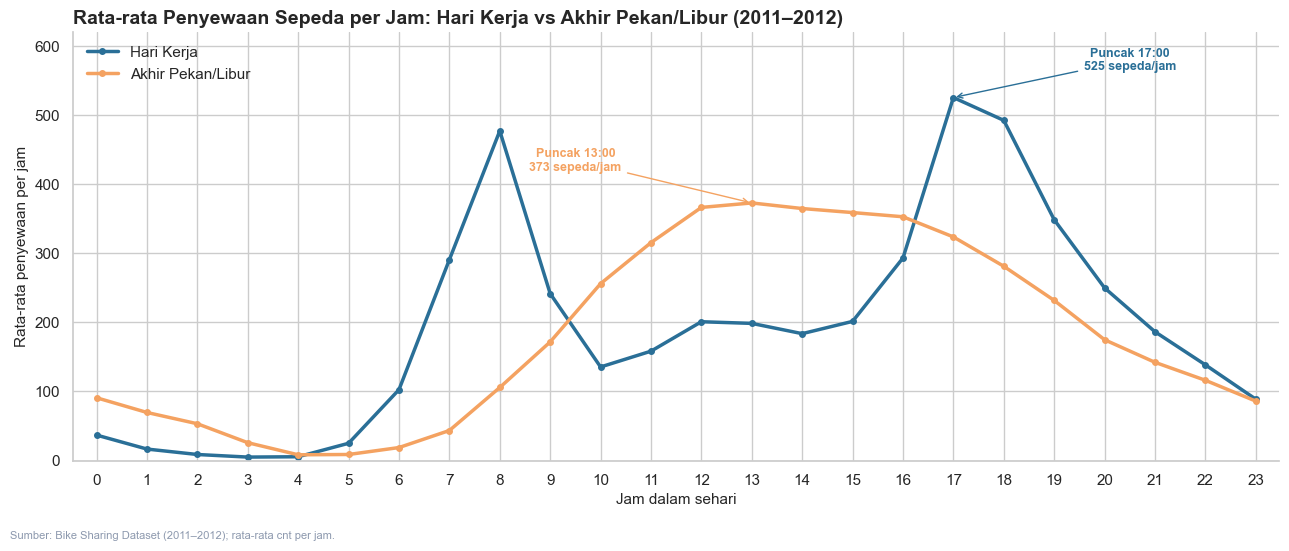

In [11]:
fig, ax = plt.subplots(figsize=(13, 5.5))
colors = {"Hari Kerja": PALETTE["primary"], "Akhir Pekan/Libur": PALETTE["accent"]}

for day_type in ["Hari Kerja", "Akhir Pekan/Libur"]:
    subset = hourly_pattern[hourly_pattern["day_type"] == day_type]
    ax.plot(
        subset["hr"],
        subset["avg_rentals"],
        marker="o",
        markersize=4,
        linewidth=2.5,
        color=colors[day_type],
        label=day_type,
    )
    peak = subset.loc[subset["avg_rentals"].idxmax()]
    ax.annotate(
        f"Puncak {peak['hr']:.0f}:00\n{peak['avg_rentals']:,.0f} sepeda/jam",
        xy=(peak["hr"], peak["avg_rentals"]),
        xytext=(20.5, 565) if day_type == "Hari Kerja" else (9.5, 420),
        fontsize=9,
        color=colors[day_type],
        fontweight="bold",
        ha="center",
        arrowprops=dict(arrowstyle="->", color=colors[day_type], lw=1),
    )

ax.set_title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2011–2012)", loc="left")
ax.set_xlabel("Jam dalam sehari")
ax.set_ylabel("Rata-rata penyewaan per jam")
ax.set_xticks(range(0, 24))
ax.set_ylim(0, 620)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, loc="upper left")
ax.margins(x=0.02)
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); rata-rata cnt per jam.", fontsize=8, color=PALETTE["muted"])
plt.show()

**Explanatory analysis:**

Grafik menegaskan perbedaan ritme permintaan: hari kerja memiliki dua puncak (perjalanan pagi dan sore), sedangkan akhir pekan memiliki satu puncak siang. Bagi tim operasional, ini berarti penambahan armada dan staf tidak bisa dilakukan dengan pola yang sama setiap hari. Pada hari kerja, prioritas adalah **07.00–09.00 dan 16.00–19.00**; pada akhir pekan, prioritas bergeser ke **10.00–16.00**. Sumbu Y dimulai dari nol sehingga perbedaan antarjam tidak dilebih-lebihkan.

### 5.2 Visualisasi Pertanyaan 2 — Pengaruh cuaca

Dua visualisasi digunakan: grafik batang untuk membandingkan rata-rata penyewaan antar kondisi cuaca, dan scatter plot untuk melihat hubungan suhu dengan permintaan harian.

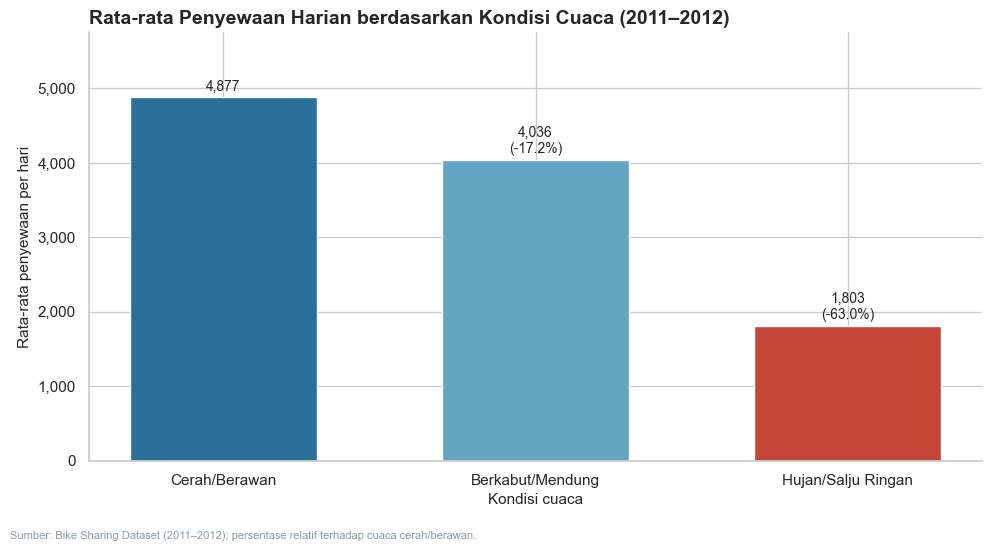

In [12]:
fig, ax = plt.subplots(figsize=(10, 5.5))
order = weather_daily.sort_values("rata_rata", ascending=False).index
bar_colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["danger"]][:len(order)]
bars = ax.bar(order, weather_daily.loc[order, "rata_rata"], color=bar_colors, width=0.6)

labels = []
for value, drop in zip(weather_daily.loc[order, "rata_rata"], weather_daily.loc[order, "penurunan_vs_cerah_pct"]):
    labels.append(f"{value:,.0f}" if abs(drop) < 0.01 else f"{value:,.0f}\n({drop:+.1f}%)")
ax.bar_label(bars, labels=labels, padding=3, fontsize=10)

ax.set_title("Rata-rata Penyewaan Harian berdasarkan Kondisi Cuaca (2011–2012)", loc="left")
ax.set_xlabel("Kondisi cuaca")
ax.set_ylabel("Rata-rata penyewaan per hari")
ax.set_ylim(0, weather_daily["rata_rata"].max() * 1.18)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); persentase relatif terhadap cuaca cerah/berawan.", fontsize=8, color=PALETTE["muted"])
plt.show()

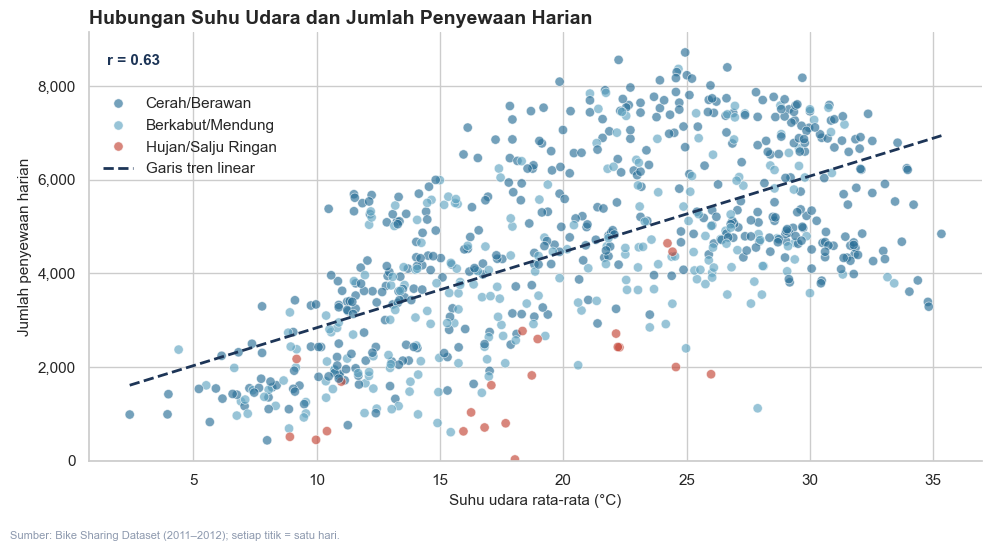

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.5))
hue_order = ["Cerah/Berawan", "Berkabut/Mendung", "Hujan/Salju Ringan"]
sns.scatterplot(
    data=day_clean,
    x="temp_c",
    y="cnt",
    hue="weather_label",
    hue_order=hue_order,
    palette={
        "Cerah/Berawan": PALETTE["primary"],
        "Berkabut/Mendung": PALETTE["secondary"],
        "Hujan/Salju Ringan": PALETTE["danger"],
    },
    alpha=0.65,
    s=45,
    ax=ax,
)

coef = np.polyfit(day_clean["temp_c"], day_clean["cnt"], 1)
x_line = np.linspace(day_clean["temp_c"].min(), day_clean["temp_c"].max(), 100)
ax.plot(x_line, np.polyval(coef, x_line), color=PALETTE["dark"], linestyle="--", linewidth=2, label="Garis tren linear")

r = day_clean["temp_c"].corr(day_clean["cnt"])
ax.text(0.02, 0.95, f"r = {r:.2f}", transform=ax.transAxes, fontsize=11, fontweight="bold", va="top", color=PALETTE["dark"])

ax.set_title("Hubungan Suhu Udara dan Jumlah Penyewaan Harian", loc="left")
ax.set_xlabel("Suhu udara rata-rata (°C)")
ax.set_ylabel("Jumlah penyewaan harian")
ax.set_ylim(bottom=0)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend(frameon=False, title=None, loc="upper left", bbox_to_anchor=(0.0, 0.88))
plt.tight_layout(rect=[0, 0.03, 1, 1])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); setiap titik = satu hari.", fontsize=8, color=PALETTE["muted"])
plt.show()

**Explanatory analysis:**

Grafik batang menunjukkan penurunan bertahap: cerah/berawan (**4.877/hari**), berkabut/mendung (**4.036/hari**, **-17,2%**), dan hujan/salju ringan (**1.803/hari**, **-63,0%**). Scatter plot menunjukkan hubungan positif antara suhu dan permintaan (**r = 0,63**), tetapi sebaran titik pada suhu yang sama cukup lebar. Artinya, suhu bukan satu-satunya faktor; hari kerja/akhir pekan, musim, dan kondisi cuaca lain juga berperan. Garis tren hanya alat bantu visual, bukan model prediksi.

### 5.3 Visualisasi Pertanyaan 3 — Segmen pengguna

Grafik 100% stacked bar digunakan untuk membandingkan komposisi pengguna antar musim, sedangkan small multiples menunjukkan pola per jam untuk masing-masing tipe pengguna pada hari kerja dan akhir pekan.

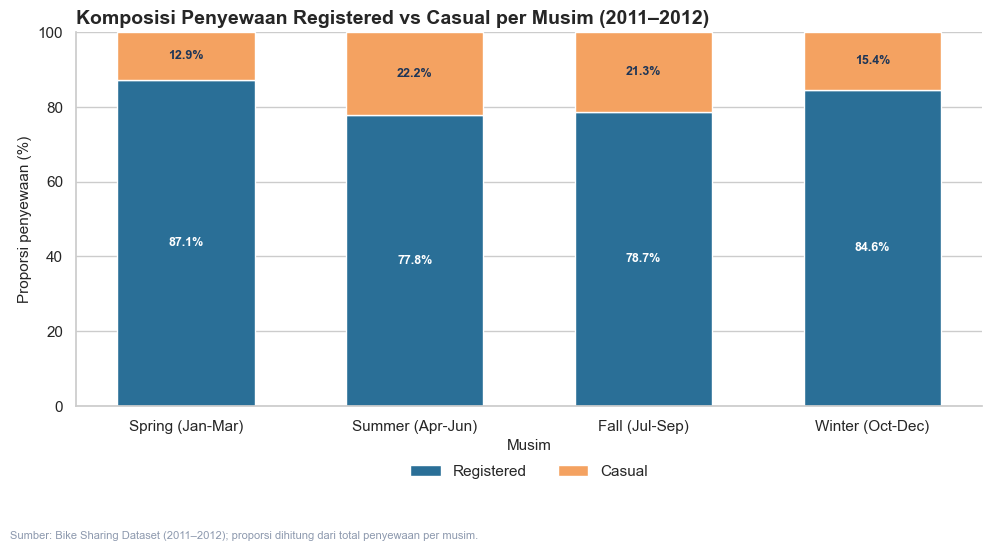

In [14]:
fig, ax = plt.subplots(figsize=(10, 5.5))
season_share = user_season[["registered", "casual"]].div(user_season["total"], axis=0) * 100
bottom = np.zeros(len(season_share))

for column, color, label in [
    ("registered", PALETTE["primary"], "Registered"),
    ("casual", PALETTE["accent"], "Casual"),
]:
    values = season_share[column].values
    ax.bar(season_share.index, values, bottom=bottom, color=color, label=label, width=0.6)
    text_color = "white" if column == "registered" else PALETTE["dark"]
    for idx, (value, base) in enumerate(zip(values, bottom)):
        if value >= 8:
            ax.text(
                idx,
                base + value / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9,
                fontweight="bold",
            )
    bottom += values

ax.set_title("Komposisi Penyewaan Registered vs Casual per Musim (2011–2012)", loc="left")
ax.set_xlabel("Musim")
ax.set_ylabel("Proporsi penyewaan (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False, ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(rect=[0, 0.06, 1, 1])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); proporsi dihitung dari total penyewaan per musim.", fontsize=8, color=PALETTE["muted"])
plt.show()

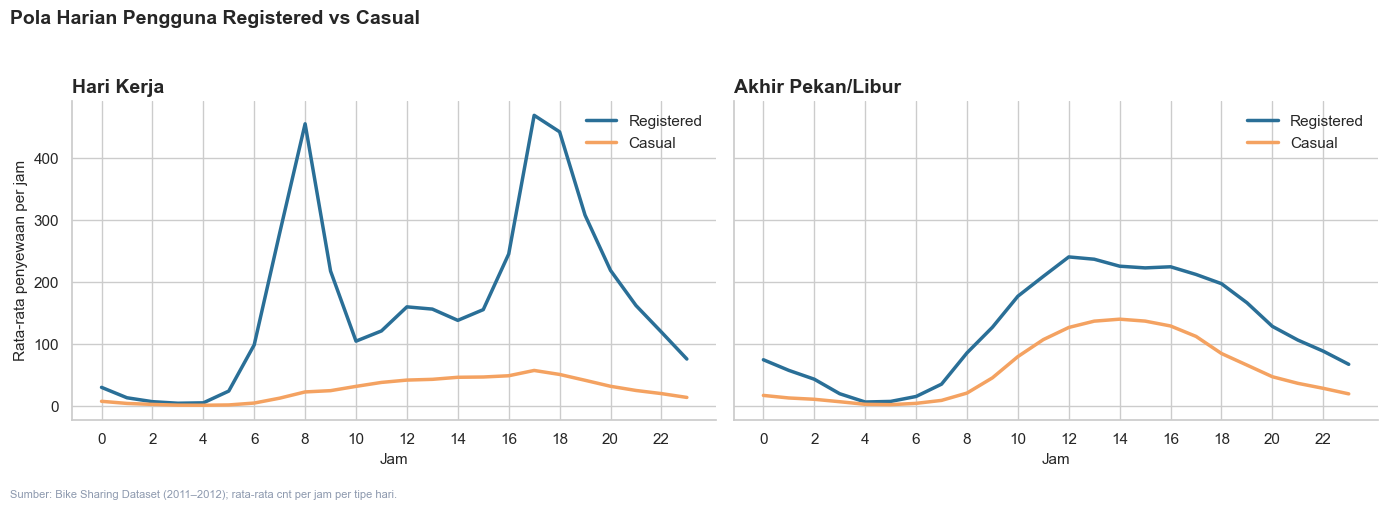

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, day_type in zip(axes, ["Hari Kerja", "Akhir Pekan/Libur"]):
    subset = hourly_pattern[hourly_pattern["day_type"] == day_type]
    ax.plot(subset["hr"], subset["avg_registered"], color=PALETTE["primary"], label="Registered", linewidth=2.5)
    ax.plot(subset["hr"], subset["avg_casual"], color=PALETTE["accent"], label="Casual", linewidth=2.5)
    ax.set_title(day_type, loc="left")
    ax.set_xlabel("Jam")
    ax.set_xticks(range(0, 24, 2))
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.legend(frameon=False)

axes[0].set_ylabel("Rata-rata penyewaan per jam")
fig.suptitle("Pola Harian Pengguna Registered vs Casual", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); rata-rata cnt per jam per tipe hari.", fontsize=8, color=PALETTE["muted"])
plt.show()

**Explanatory analysis:**

Registered mendominasi seluruh musim (77,8%–87,1%), tetapi casual memiliki proporsi terbesar pada Summer (22,2%) dan Fall (21,3%). Pola per jam memperlihatkan bahwa registered mengikuti ritme komuter (puncak 08.00 dan 17.00), sedangkan casual lebih aktif pada siang hari, terutama akhir pekan (puncak 14.00). Ini membuka peluang kampanye membership yang ditargetkan pada pengguna casual di akhir pekan musim hangat.

### 5.4 Visualisasi Analisis Lanjutan — Segmentasi permintaan

Grafik batang menampilkan rata-rata penyewaan per segmen, sedangkan stacked bar menunjukkan komposisi musim pada setiap segmen.

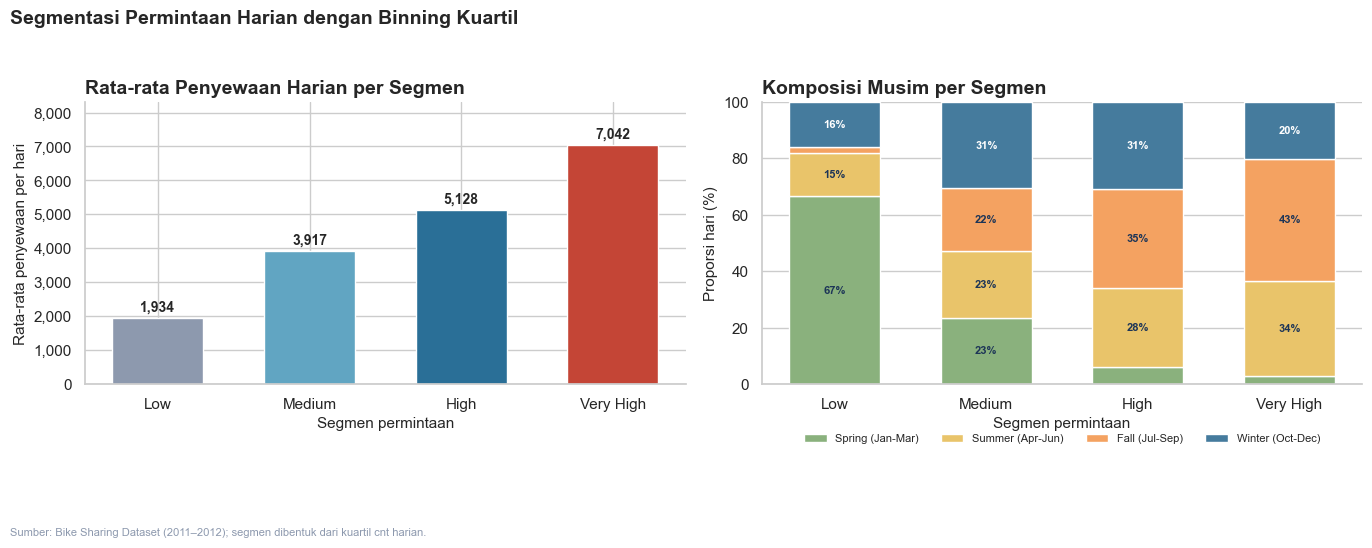

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

segment_colors = [PALETTE["muted"], PALETTE["secondary"], PALETTE["primary"], PALETTE["danger"]]
bars = axes[0].bar(seg_order, segment_profile.loc[seg_order, "rata_rata_cnt"], color=segment_colors, width=0.6)
axes[0].bar_label(
    bars,
    labels=[f"{value:,.0f}" for value in segment_profile.loc[seg_order, "rata_rata_cnt"]],
    padding=3,
    fontsize=10,
    fontweight="bold",
)
axes[0].set_title("Rata-rata Penyewaan Harian per Segmen", loc="left")
axes[0].set_xlabel("Segmen permintaan")
axes[0].set_ylabel("Rata-rata penyewaan per hari")
axes[0].set_ylim(0, segment_profile["rata_rata_cnt"].max() * 1.18)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

season_colors = ["#8AB17D", "#E9C46A", "#F4A261", "#457B9D"]
bottom = np.zeros(len(seg_order))
season_segment_plot = season_segment.reindex(seg_order)[season_order]

for season, color in zip(season_order, season_colors):
    values = season_segment_plot[season].values
    axes[1].bar(seg_order, values, bottom=bottom, color=color, label=season, width=0.6)
    text_color = "white" if season == "Winter (Oct-Dec)" else PALETTE["dark"]
    for idx, (value, base) in enumerate(zip(values, bottom)):
        if value >= 10:
            axes[1].text(
                idx,
                base + value / 2,
                f"{value:.0f}%",
                ha="center",
                va="center",
                color=text_color,
                fontsize=8,
                fontweight="bold",
            )
    bottom += values

axes[1].set_title("Komposisi Musim per Segmen", loc="left")
axes[1].set_xlabel("Segmen permintaan")
axes[1].set_ylabel("Proporsi hari (%)")
axes[1].set_ylim(0, 100)
axes[1].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4)

fig.suptitle("Segmentasi Permintaan Harian dengan Binning Kuartil", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(rect=[0, 0.10, 1, 0.95])
fig.text(0.01, 0.005, "Sumber: Bike Sharing Dataset (2011–2012); segmen dibentuk dari kuartil cnt harian.", fontsize=8, color=PALETTE["muted"])
plt.show()

**Explanatory analysis:**

Segmentasi memperjelas bahwa permintaan tinggi sangat terkait dengan cuaca hangat dan cerah: Very High memiliki rata-rata **7.042/hari** dan **77%** hari cerah, sedangkan Low hanya **1.934/hari** dan **66,7%** hari berada di Spring. Komposisi musim pada Very High (Fall 43,2%; Summer 33,9%) dapat menjadi dasar perencanaan armada musiman. Karena segmen ini juga didominasi hari kerja (68,9%), kapasitas tambahan perlu disiapkan untuk hari kerja cerah, bukan hanya akhir pekan.

## 6. Conclusion & Recommendation

### 6.1 Kesimpulan

**Kesimpulan Pertanyaan 1 — Pola permintaan per jam:**
Permintaan pada hari kerja bersifat bimodal dengan puncak pagi **08.00 (477 sepeda/jam)** dan puncak sore **17.00 (525,3 sepeda/jam)**, serta titik terendah **03.00 (4,9 sepeda/jam)**. Pada akhir pekan/libur, permintaan memuncak satu kali pada **13.00 (372,7 sepeda/jam)**. Pola ini menunjukkan bahwa jam sibuk commuter dan waktu rekreasi siang membutuhkan strategi armada yang berbeda.

**Kesimpulan Pertanyaan 2 — Pengaruh cuaca:**
Cuaca berpengaruh kuat terhadap permintaan. Dibanding cuaca cerah/berawan (**4.876,8/hari**), cuaca berkabut/mendung menurunkan permintaan **17,2%** dan hujan/salju ringan menurunkan **63,0%** menjadi **1.803,3/hari**. Suhu aktual dan suhu efektif memiliki korelasi positif kuat (**r = 0,63**), sedangkan angin (**r = -0,24**) dan kelembapan (**r = -0,11**) berkorelasi negatif lemah. Suhu **20–30°C** menghasilkan rata-rata tertinggi (**5.661,7/hari**).

**Kesimpulan Pertanyaan 3 — Segmen pengguna:**
Pengguna registered mendominasi **81,2%** penyewaan, sedangkan casual **18,8%**. Proporsi casual lebih tinggi pada akhir pekan/libur (**31,7%**) dan musim Summer/Fall (**22,2%/21,3%**). Total penyewaan tumbuh **64,9%** YoY; registered tumbuh **68,4%**, lebih cepat dari casual (**50,8%**). Casual tetap menjadi segmen yang potensial untuk dikonversi, terutama pada akhir pekan musim hangat.

**Kesimpulan Analisis Lanjutan — Segmentasi permintaan:**
Segmen Very High (rata-rata **7.042,5/hari**) didominasi cuaca cerah (**77,0%**), suhu hangat (**25,4°C**), dan musim Fall/Summer (**43,2%/33,9%**), dengan **68,9%** berupa hari kerja. Segmen Low (rata-rata **1.933,6/hari**) didominasi Spring (**66,7%**). Segmentasi ini dapat digunakan untuk perencanaan armada dan perawatan yang lebih tepat sasaran.

### 6.2 Rekomendasi Action Item

| Prioritas | Action Item | Dasar Insight | Metrik Keberhasilan | Waktu |
|---|---|---|---|---|
| Tinggi | **Rebalancing armada dan staf berbasis jam sibuk.** Tambah kapasitas di stasiun padat pada hari kerja pukul **07.00–09.00** dan **16.00–19.00** (terutama 17.00), serta akhir pekan pukul **10.00–16.00**. | Q1: puncak 525 sepeda/jam pada hari kerja dan 373 sepeda/jam pada akhir pekan. | Ketersediaan sepeda per stasiun, waktu tunggu, dan tingkat kekurangan sepeda turun. | 1–3 bulan |
| Tinggi | **Rencana operasional berbasis cuaca.** Kurangi repositioning armada pada hari hujan/salju ringan, alihkan ke perawatan; pada hari cerah dan hangat, tambah armada dan staf. | Q2: hujan menurunkan permintaan 63%; suhu 20–30°C menghasilkan permintaan tertinggi. | Utilisasi armada, biaya repositioning per penyewaan, dan revenue per available bike. | 1–3 bulan |
| Sedang | **Kampanye konversi casual → registered.** Targetkan pengguna casual pada akhir pekan dan musim Summer/Fall dengan trial membership, diskon perpanjangan, atau poin loyalitas. | Q3: casual 31,7% pada akhir pekan dan 22,2% pada Summer; casual tumbuh 50,8% YoY. | Conversion rate casual → registered, registered share, dan retensi 3 bulan. | 3–6 bulan |
| Sedang | **Perencanaan armada musiman berbasis segmen.** Tambah armada sebelum hari Very High (cerah, hangat, Fall/Summer); jadwalkan perawatan pada hari Low (Spring, hujan). | Analisis lanjutan: Very High 7.042/hari vs Low 1.934/hari. | Armada tersedia saat permintaan tinggi, downtime perawatan, dan biaya penyimpanan. | Musiman |
| Rendah | **Perbaiki kualitas data operasional.** Lengkapi 165 timestamp jam yang hilang dan validasi sensor kelembapan; tambahkan data stasiun/koordinat untuk analisis geospasial berikutnya. | Assessing: 165 timestamp hilang, 1 hari dan 22 jam dengan kelembapan 0%. | Data completeness >99%, jumlah anomali sensor turun. | 1–2 siklus data |

## 7. Ringkasan Insight per Tahapan Analisis

| Tahap | Insight Utama |
|---|---|
| **Gathering Data** | Dataset mencakup 731 hari dan 17.379 jam pada 2011–2012, dengan fitur musim, cuaca, suhu, kelembapan, angin, serta jumlah pengguna casual/registered. |
| **Assessing Data** | Tidak ada missing value dan duplikasi baris, tetapi ditemukan 165 timestamp jam yang hilang, kelembapan 0% (1 hari; 22 jam), kode kategori yang belum dilabeli, satuan ternormalisasi, dan 505 outlier per jam yang valid sebagai lonjakan permintaan. |
| **Cleaning Data** | Tanggal dikonversi ke datetime, kategori dilabeli, satuan diubah ke °C/%/km/jam, kelembapan 0% diimputasi dengan median bulan (dan bulan-jam), serta fitur turunan ditambahkan. Tidak ada baris yang dihapus. |
| **EDA Pertanyaan 1** | Hari kerja memiliki pola bimodal (08.00 dan 17.00); akhir pekan memiliki satu puncak siang (13.00). |
| **EDA Pertanyaan 2** | Cuaca cerah/berawan memiliki permintaan tertinggi; hujan/salju ringan menurunkan permintaan 63%; suhu berkorelasi positif kuat (r = 0,63). |
| **EDA Pertanyaan 3** | Registered mendominasi 81,2%; casual lebih tinggi pada akhir pekan (31,7%) dan Summer/Fall; registered tumbuh lebih cepat (68,4% vs 50,8%). |
| **Analisis Lanjutan** | Binning kuartil menghasilkan empat segmen permintaan; Very High (7.042/hari) didominasi cuaca cerah, suhu hangat, dan Fall/Summer. |
| **Visualization & Explanatory** | Visualisasi menegaskan pola jam sibuk, penurunan permintaan saat hujan, dominasi registered, dan karakteristik segmen Very High. Rekomendasi diarahkan pada rebalancing armada, operasi berbasis cuaca, dan konversi casual. |

## 8. Keterbatasan dan Next Steps

**Keterbatasan:**

- Dataset tidak memiliki ID pelanggan dan koordinat stasiun, sehingga **RFM analysis** dan **geospatial analysis** tidak dapat dilakukan secara valid.
- Data hanya mencakup 2011–2012; pola dapat berbeda dengan kondisi saat ini.
- Terdapat 165 timestamp per jam yang hilang, sebagian besar pada dini hari (03.00–04.00), sehingga analisis per jam tetap cukup robust tetapi tidak sempurna.
- Jumlah hari hujan/salju ringan hanya 21 hari, sehingga estimasi dampak cuaca ekstrem memiliki ketidakpastian tinggi.
- `workingday = 0` menggabungkan akhir pekan dan hari libur; keduanya tidak dapat dipisahkan.
- Tidak tersedia data harga, pendapatan, atau kapasitas armada aktual, sehingga analisis belum sampai pada optimasi biaya.

**Next Steps:**

1. Menambahkan data stasiun dan koordinat untuk analisis geospasial dan rebalancing berbasis lokasi.
2. Menambahkan ID pelanggan (jika tersedia) untuk RFM analysis.
3. Mengintegrasikan prakiraan cuaca untuk perencanaan armada harian.
4. Membangun model prediksi permintaan (di luar cakupan proyek ini) setelah data tambahan tersedia.
5. Melakukan uji A/B untuk kampanye konversi casual → registered.

## 9. Referensi

- Fanaee-T, H., & Gama, J. (2013). *Event labeling combining ensemble detectors and background knowledge*. Progress in Artificial Intelligence, 2, 113–127.
- UCI Machine Learning Repository. *Bike Sharing Dataset*. https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset
- Tufte, E. R. (2001). *The Visual Display of Quantitative Information* (2nd ed.). Graphics Press.
- Dicoding. *Belajar Analisis Data dengan Python* — materi Data Wrangling, EDA, Visualisasi Data, dan Dashboard.

## 10. Dashboard Streamlit

Dashboard interaktif dibuat di `dashboard/dashboard.py` dan menggunakan data bersih:

- `dashboard/main_data.csv` — data per jam.
- `dashboard/main_data_daily.csv` — data harian.

Menjalankan dari root proyek:

```bash
pip install -r requirements.txt
streamlit run dashboard/dashboard.py
```

Dashboard menyediakan filter tanggal, musim, tipe hari, dan kondisi cuaca, serta tab untuk ringkasan, pola jam, cuaca, segmen pengguna, segmentasi permintaan, dan kesimpulan.

**Live Demo:** https://abhiprayaa29-bike-sharing-dashboard-dashboarddashboard-j5y8xb.streamlit.app/ (URL juga tersimpan di `url.txt`).